> **Web-runner version** of the Colab participant notebook. `data_dir` and `out_dir` are parameters set by the server; the last cell exports map layers for the viewer. Everything else is the original teaching material.

# Module 5 – Predictive Spatial Modelling in R
**Participant notebook (R in Google Colab)**

This notebook contains every code cell of the training manual, in the same order and with the same step numbers, so you can run it alongside the manual. Run the cells from top to bottom; each topic depends on objects created earlier.

Before starting: **Runtime → Change runtime type → Language: R**. Then run the setup cells. When a session resets, run the setup cells again and continue where you were.

Text cells give the step; the manual has the explanations, the expected outputs and the figures, so compare your output with the manual after each cell.

# Introduction to Module 5

### Visual roadmap — Module 5 at a glance

*This roadmap gives the big picture of the full predictive spatial modelling workflow before you begin the topic-by-topic lessons.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  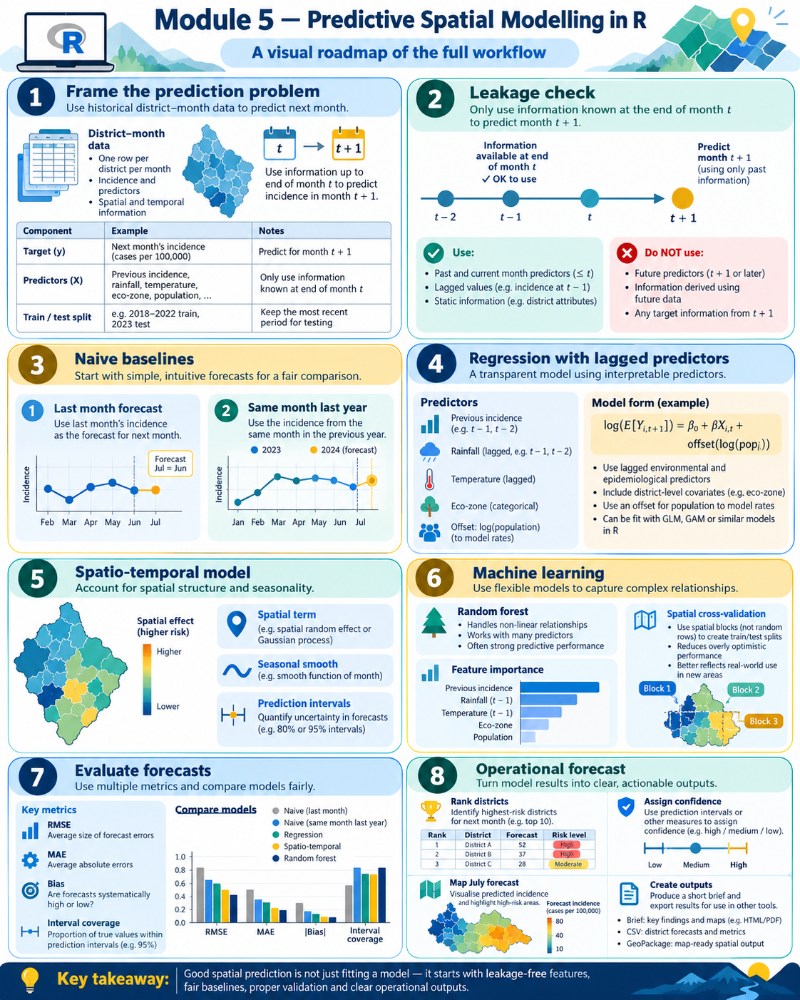
</div>


## Setting up: Google Colab and R

The routine is the one from the earlier modules; only the file names and the package list change. ranger (random forests) and pROC (ROC curves) are the two additions.

In [ ]:
# Parameters: the web app (papermill) overrides these for every run.
data_dir    <- "/data/module5_data"
out_dir     <- "/srv/jobs/outputs"

In [ ]:
project_dir <- file.path(out_dir, "project")      # Module 2 builds its project folder here
dir.create(out_dir, showWarnings = FALSE, recursive = TRUE)
# a data zip with one extra top-level folder: step into it
.sub <- list.dirs(data_dir, recursive = FALSE); .fil <- list.files(data_dir)
if (length(.sub) == 1 && length(.fil) == 0) data_dir <- .sub
cat("Data directory:", data_dir, "\n")
list.files(data_dir, recursive = TRUE)

# Find panel.rds even if the dataset has an extra folder
panel_path <- list.files(data_dir, pattern = "^panel\\.rds$", recursive = TRUE, full.names = TRUE)
if (length(panel_path) != 1) stop("Expected exactly one panel.rds file, but found: ", length(panel_path))
data_dir <- dirname(panel_path)

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
suppressPackageStartupMessages({
  library(tidyverse); library(sf); library(spdep); library(MASS); library(broom); library(mgcv)
  library(ranger); library(pROC); library(scales); library(patchwork)
})
select <- dplyr::select
options(width = 95)
dir.create(out_dir, showWarnings = FALSE)

### Loading the panel

In [ ]:
panel_path <- file.path(data_dir, "panel.rds")
district_path <- file.path(data_dir, "ghana_districts.gpkg")

stopifnot(file.exists(panel_path))
stopifnot(file.exists(district_path))

panel <- readr::read_rds(panel_path)

districts <- sf::st_read(
  district_path,
  quiet = TRUE
)

panel <- panel |>
  left_join(
    districts |> st_drop_geometry(),
    by = "adm2_code"
  )

cat("Panel rows:", nrow(panel), "\n")
cat("Districts:", nrow(districts), "\n")

panel |>
  count(split) |>
  mutate(months = n / nrow(districts))

range(
  panel$month[panel$split == "train"],
  na.rm = TRUE
)

range(
  panel$month[panel$split == "test"],
  na.rm = TRUE
)

Eighteen training months and six test months, split by date in Module 2. Nothing from July to December 2024 is used to fit anything in this module.

# Topic 1 – Framing A Spatial Prediction Problem

### Visual explainer: Framing the prediction problem

*Use this before Topic 1 to understand what is being predicted, what the target is, and which predictors are allowed at prediction time.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  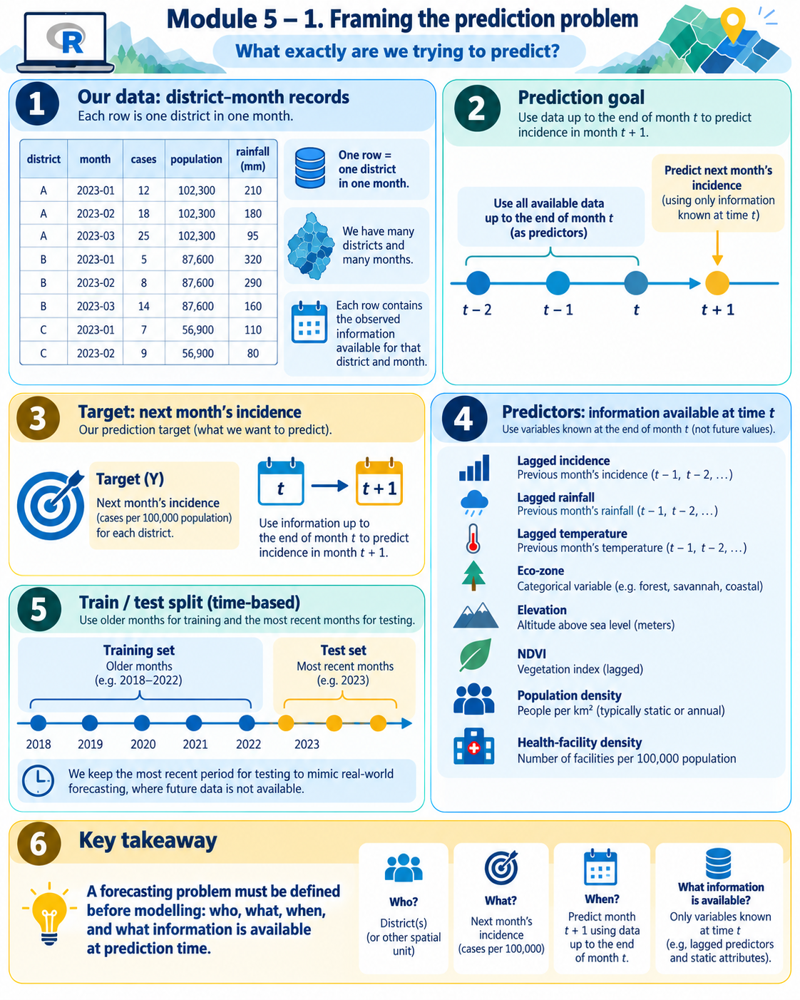
</div>


## 1.4 Step by step in R with Ama's data

Step 1. The prediction statement, written as a table so that it can be checked and kept.

In [ ]:
# the prediction statement, as a table the whole team can check
tibble(item  = c("Outcome", "Unit", "Prediction time", "Horizon", "Predictors allowed", "Training period", "Test period", "Metric", "Intended use"),
       value = c("confirmed malaria incidence per 1,000 (and cases)", "district-month", "end of month t, after the DHIMS2 export for t",
                 "month t + 1", "anything known at the end of month t: lags of rainfall, temperature and cases; static district data; the calendar",
                 "January 2023 to June 2024 (18 months)", "July to December 2024 (6 months)", "RMSE and MAE of incidence per 1,000",
                 "position commodities and nets before the next month; not to confirm anything")) |> print(n = 20)

### Visual explainer: Leakage check

*This explains what data leakage is in next-month forecasting and which variables are safe or unsafe to use.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  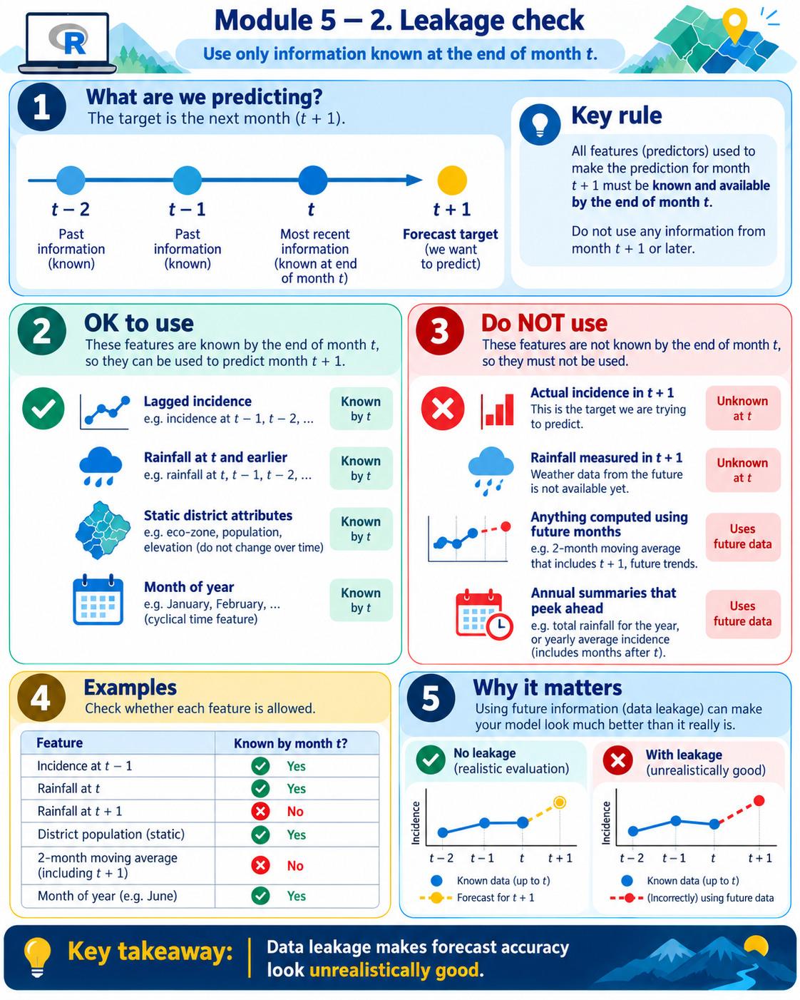
</div>


Step 2. The leakage test on the panel's columns.

In [ ]:
# the leakage test: for each column, is it known at the end of month t when predicting t + 1?
tibble(column = c("rain_mm", "tmean_c", "rain_lag1", "rain_lag2", "tmean_lag1", "cases_lag1", "reporting_rate", "elev_m / ndvi / pop_density / fac_per_10k", "month_of_year / season", "confirmed (t + 1)"),
       known_at_prediction_time = c("NO: this is next month's rainfall", "NO", "yes", "yes", "yes", "yes: last month's export", "for month t yes; for t + 1 no",
                                    "yes (static)", "yes (calendar)", "NO: the outcome")) |> print(n = 20)

Step 3. The feature set that passes the test, with the lagged case count set to missing when last month was flagged or unreported, the usable rows and the split.

In [ ]:
# the feature set that passes the test, the usable rows, and the split
model_df <- panel |>
  arrange(adm2_code, month) |> group_by(adm2_code) |>
  mutate(lag_flagged = lag(flag_outlier, 1) | !lag(reported, 1),                      # was last month itself usable?
         rate_lag1 = lag(reporting_rate, 1)) |> ungroup() |>                            # last month's reporting rate: known
  mutate(inc_lag1 = if_else(lag_flagged %in% TRUE, NA_real_, cases_lag1 / population * 1000),
         logdens = log(pop_density), elev100 = elev_m / 100, ndvi10 = ndvi * 10,
         rain_lag1_100 = rain_lag1 / 100, rain_lag2_100 = rain_lag2 / 100,
         moy = factor(month_of_year), eco_zone = factor(eco_zone), id = factor(adm2_code, levels = districts$adm2_code)) |>
  filter(reported, !flag_outlier, !is.na(inc_lag1), !is.na(rain_lag2))
model_df |> count(split)
train <- model_df |> filter(split == "train"); test <- model_df |> filter(split == "test")
range(test$month)

In [ ]:
ls()

3,330 training and 1,213 test district-months remain after requiring a usable current month, a usable previous month and two months of rainfall history. The rows lost are the price of honesty: a forecast cannot be made for a district whose last month is unknown.

### Visual explainer: Naive forecasting baselines

*This introduces the two simple baselines that every more complex forecasting model should beat.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  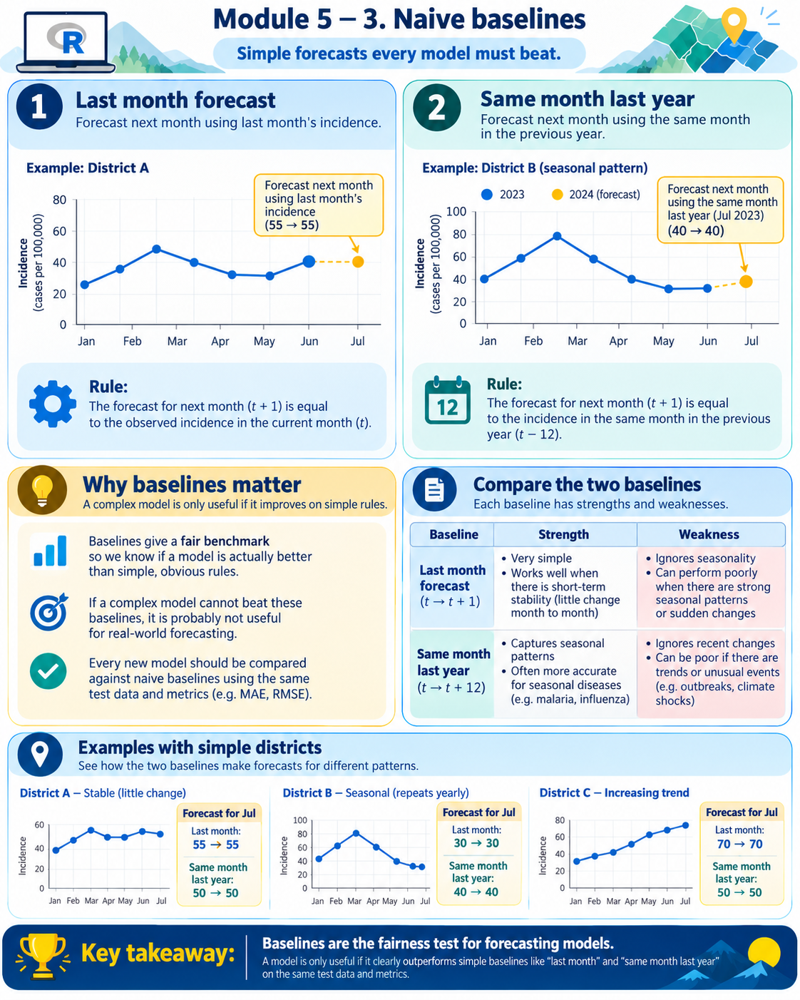
</div>


Step 4. The two naive baselines on the test months.

In [ ]:
# two naive baselines any model must beat: last month, and the same month last year (the seasonal baseline)
rmse <- function(obs, pred) sqrt(mean((obs - pred)^2)); mae <- function(obs, pred) mean(abs(obs - pred))
seasonal <- train |> group_by(adm2_code, month_of_year) |> summarise(inc_seasonal = mean(incidence_1000), .groups = "drop")
test <- test |> left_join(seasonal, by = c("adm2_code", "month_of_year"))
sum(is.na(test$inc_seasonal))                                  # districts with no usable same-month-last-year value
test <- test |> mutate(inc_seasonal = if_else(is.na(inc_seasonal), inc_lag1, inc_seasonal))
baselines <- tibble(model = c("Naive: last month", "Naive: same month last year"),
                    RMSE = c(rmse(test$incidence_1000, test$inc_lag1), rmse(test$incidence_1000, test$inc_seasonal)),
                    MAE  = c(mae(test$incidence_1000, test$inc_lag1),  mae(test$incidence_1000, test$inc_seasonal))) |> mutate(across(c(RMSE, MAE), ~ round(.x, 2)))
baselines

243 test rows have no usable value for the same month last year (that month was not reported in 2023) and fall back to last month. The seasonal baseline (RMSE 3.02, MAE 1.90) is much better than last month (4.44, 2.75), because the season moves fast in the north and last month is already out of date. The number to beat is 3.02.

In [ ]:
test |> filter(adm2_name %in% c("Bolgatanga Municipal", "Kumasi Metropolitan", "Nabdam")) |>
  select(adm2_name, month, observed = incidence_1000, last_month = inc_lag1, seasonal = inc_seasonal) |>
  pivot_longer(-c(adm2_name, month), names_to = "series") |>
  ggplot(aes(month, value, colour = series)) + geom_line(linewidth = 1) + geom_point() + facet_wrap(~ adm2_name, scales = "free_y") +
  scale_colour_manual(values = c(observed = "black", last_month = "#C9A063", seasonal = "#9DB4CC")) +
  labs(title = "The two naive baselines against what happened, July to December 2024", x = NULL, y = "incidence per 1,000", colour = NULL) + theme_minimal() + theme(legend.position = "bottom")

## 1.8 Trial test 1

Answer the trial test on paper (manual section 1.8). Answers are at the end of the manual.

# Topic 2 – Regression Forecasts with Lagged Predictors

### Visual explainer: Regression forecasts with lagged predictors

*This prepares you for Topic 2 by showing how lagged predictors, offsets and regression coefficients work in next-month incidence forecasting.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  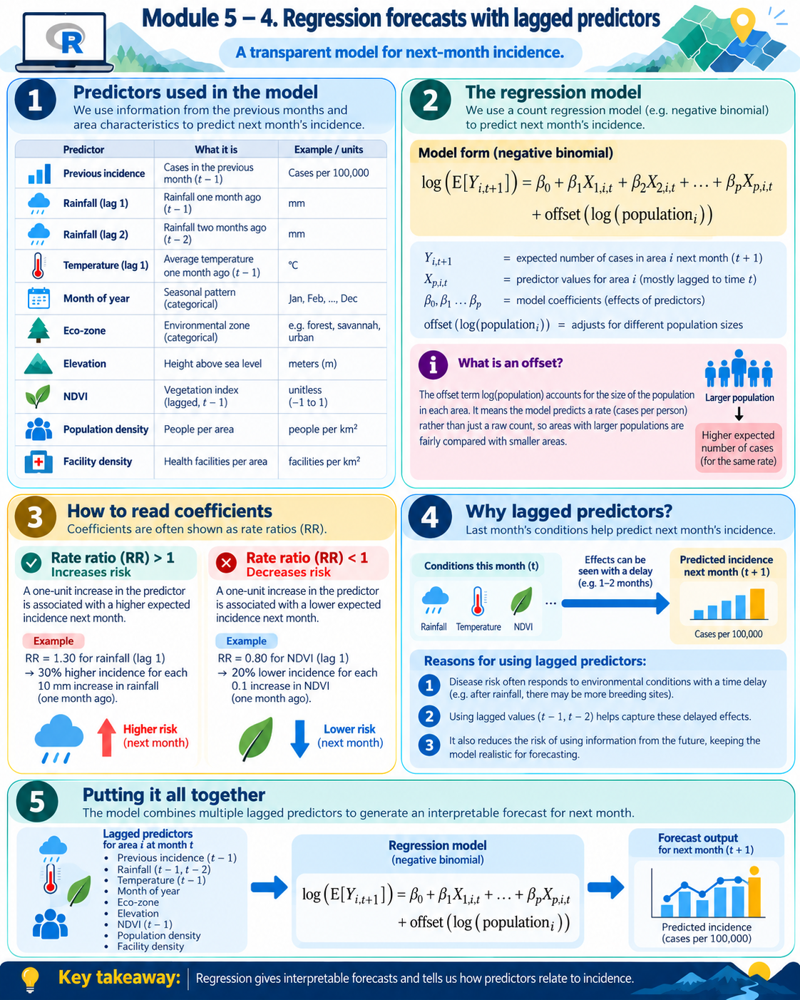
</div>


## 2.4 Step by step in R with Ama's data

Step 1. Fit on the training months and read the rate ratios (the twelve month terms are hidden for space).

In [ ]:
f_glm <- confirmed ~ log1p(inc_lag1) + rain_lag1_100 + rain_lag2_100 + tmean_lag1 + moy + eco_zone + elev100 + ndvi10 + logdens + fac_per_10k + offset(log(population))
fit_nb <- glm.nb(f_glm, data = train)
tidy(fit_nb, exponentiate = TRUE, conf.int = TRUE) |> filter(!str_detect(term, "^moy")) |> mutate(across(where(is.numeric), ~ round(.x, 3))) |> print(n = 20)
round(fit_nb$theta, 1)

Theta is 44.9: much less over-dispersion than in Module 4's annual model, because last month's incidence has absorbed most of the district-to-district variation.

Step 2. Predict the six test months and score.

In [ ]:
test$pred_glm <- as.numeric(predict(fit_nb, newdata = test, type = "response")) / test$population * 1000
scores <- bind_rows(baselines, tibble(model = "NB regression", RMSE = round(rmse(test$incidence_1000, test$pred_glm), 2), MAE = round(mae(test$incidence_1000, test$pred_glm), 2)))
scores
test |> group_by(month) |> summarise(RMSE_glm = round(rmse(incidence_1000, pred_glm), 2), RMSE_seasonal = round(rmse(incidence_1000, inc_seasonal), 2), RMSE_last = round(rmse(incidence_1000, inc_lag1), 2))

In [ ]:
test |> mutate(mon = factor(format(month, "%b %Y"), levels = format(sort(unique(month)), "%b %Y"))) |>
  ggplot(aes(pred_glm, incidence_1000)) + geom_abline(colour = "grey50") + geom_point(alpha = 0.3, size = 0.8, colour = "#010066") +
  facet_wrap(~ mon, nrow = 2) + coord_equal() +
  labs(title = "Negative-binomial regression: predicted against observed, test months", x = "predicted per 1,000", y = "observed per 1,000") + theme_minimal()

Step 3. Where the regression is wrong, and whether its errors are clustered.

In [ ]:
# where is the regression wrong? district-level error over the six test months, and its spatial structure
err_glm <- test |> group_by(adm2_code) |> summarise(mae_glm = mae(incidence_1000, pred_glm), bias_glm = mean(pred_glm - incidence_1000))
nb_q <- poly2nb(districts, queen = TRUE); names(nb_q) <- districts$adm2_code
lw_q <- nb2listw(nb_q, style = "W", zero.policy = TRUE)
e <- districts |> st_drop_geometry() |> select(adm2_code) |> left_join(err_glm, by = "adm2_code") |> mutate(bias_glm = replace_na(bias_glm, 0))
moran.test(e$bias_glm, lw_q, zero.policy = TRUE)$estimate[1] |> round(3)
err_glm |> left_join(districts |> st_drop_geometry(), by = "adm2_code") |> arrange(-mae_glm) |> select(adm2_name, region, mae_glm, bias_glm) |> mutate(across(c(mae_glm, bias_glm), ~ round(.x, 1))) |> head(5)

In [ ]:
districts |> left_join(err_glm, by = "adm2_code") |> ggplot() + geom_sf(aes(fill = bias_glm), colour = "white", linewidth = 0.1) +
  scale_fill_gradient2("mean bias\n(pred - obs)", low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0, limits = c(-5, 5), oob = squish) +
  labs(title = "Regression bias by district, July to December 2024", subtitle = "red: predicted too high; blue: too low (capped at +/- 5 per 1,000)") + theme_minimal()

## 2.8 Trial test 2

Answer the trial test on paper (manual section 2.8). Answers are at the end of the manual.

# Topic 3 – Spatio-Temporal Models and Prediction Intervals

### Visual explainer: Spatio-temporal models and prediction intervals

*This explains why we add spatial structure, seasonality and prediction intervals in Topic 3.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  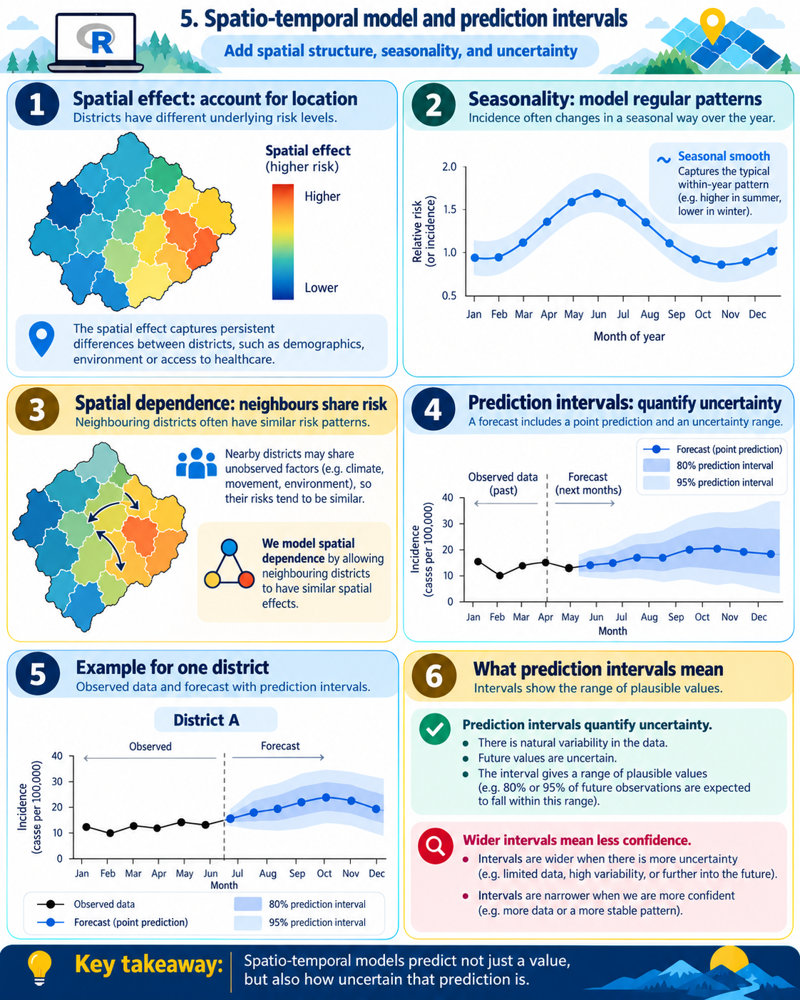
</div>


## 3.4 Step by step in R with Ama's data

Step 1. The spatio-temporal model: lagged predictors, a cyclic seasonal smooth, the Module 4 spatial term, the offset.

In [ ]:
# the Module 4 spatial term, plus a smooth seasonal cycle, plus the lagged predictors
f_st <- confirmed ~ log1p(inc_lag1) + rain_lag1_100 + rain_lag2_100 + tmean_lag1 + eco_zone + elev100 + ndvi10 + logdens + fac_per_10k +
  s(month_of_year, bs = "cc", k = 8) + s(id, bs = "mrf", xt = list(nb = nb_q)) + offset(log(population))
m_st <- gam(f_st, family = nb(), data = train, method = "REML", knots = list(month_of_year = c(0.5, 12.5)))
summary(m_st)$s.table
round(m_st$family$getTheta(TRUE), 1)

In [ ]:
p1 <- plot(m_st, select = 1, shade = TRUE, main = "Seasonal smooth (log scale)", xlab = "month of year")

Step 2. Point forecasts for the test months and the score.

In [ ]:
# point forecasts for the test months, and the score
test$pred_st <- as.numeric(predict(m_st, newdata = test, type = "response")) / test$population * 1000
scores <- bind_rows(scores, tibble(model = "Spatio-temporal (mgcv)", RMSE = round(rmse(test$incidence_1000, test$pred_st), 2), MAE = round(mae(test$incidence_1000, test$pred_st), 2)))
scores

Step 3. Prediction intervals from posterior draws, their coverage, and one district's forecasts with intervals.

In [ ]:
# prediction intervals: posterior draws of the coefficients, then negative-binomial draws of the count
Xp   <- predict(m_st, newdata = test, type = "lpmatrix")
beta <- rmvn(500, coef(m_st), vcov(m_st))
mu   <- exp(Xp %*% t(beta) + log(test$population))              # 500 draws of the expected count per test row
theta <- m_st$family$getTheta(TRUE)
draws <- matrix(rnbinom(length(mu), size = theta, mu = mu), nrow = nrow(mu)) / test$population * 1000
test <- test |> mutate(st_lo = apply(draws, 1, quantile, 0.05), st_hi = apply(draws, 1, quantile, 0.95),
                       covered = incidence_1000 >= st_lo & incidence_1000 <= st_hi, width = st_hi - st_lo)
test |> summarise(coverage_90 = round(mean(covered), 2), median_width = round(median(width), 1))
test |> filter(adm2_name == "Bolgatanga Municipal") |> select(month, incidence_1000, pred_st, st_lo, st_hi) |> mutate(across(-month, ~ round(.x, 1)))

In [ ]:
sel <- test |> filter(adm2_name %in% c("Bolgatanga Municipal", "Kumasi Metropolitan", "Nabdam", "Sekondi Takoradi Metropolitan"))
ggplot(sel, aes(month)) + geom_ribbon(aes(ymin = st_lo, ymax = st_hi), fill = "#9DB4CC", alpha = 0.5) +
  geom_line(aes(y = pred_st), colour = "#010066", linewidth = 1) + geom_point(aes(y = incidence_1000), colour = "black", size = 2) +
  facet_wrap(~ adm2_name, scales = "free_y") + labs(title = "Spatio-temporal model: one-month-ahead forecasts", subtitle = "line: forecast; band: 90% prediction interval; points: observed", x = NULL, y = "incidence per 1,000") + theme_minimal()

### The same model in R-INLA (for reference; not run here)

The INLA version adds a first-order random walk over months for the seasonal and trend component and keeps the BYM2 spatial term; predictions for the test months are obtained by setting their outcome to NA and asking INLA to compute the fitted values. It runs in minutes and is the model family behind CHAP, the climate-health modelling app inside DHIS2.

**For reference only (needs INLA installed from its own repository):** the same model in R-INLA.

```r
library(INLA)                                   # install from https://inla.r-inla-download.org/R/stable
nb2INLA("/content/ghana.adj", nb_q); g <- inla.read.graph("/content/ghana.adj")
d <- bind_rows(train, test) |> mutate(idx = as.integer(id), t = as.integer(factor(month)),
                                      y = if_else(split == "test", NA_real_, confirmed))   # hide the test months
res <- inla(y ~ log1p(inc_lag1) + rain_lag1_100 + rain_lag2_100 + tmean_lag1 + eco_zone + elev100 + ndvi10 + logdens + fac_per_10k +
              f(idx, model = "bym2", graph = g) + f(t, model = "rw1", cyclic = FALSE),
            family = "nbinomial", data = d, E = population,
            control.predictor = list(compute = TRUE, link = 1), control.compute = list(dic = TRUE, waic = TRUE))
d$pred_inla <- res$summary.fitted.values$mean * 1000        # posterior mean incidence per 1,000; quantiles alongside
```

## 3.8 Trial test 3

Answer the trial test on paper (manual section 3.8). Answers are at the end of the manual.

# Topic 4 – Machine Learning with Spatial Cross-Validation

### Visual explainer: Machine learning with spatial cross-validation

*This introduces random forests, spatial block cross-validation and why random row splits can look unrealistically good.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  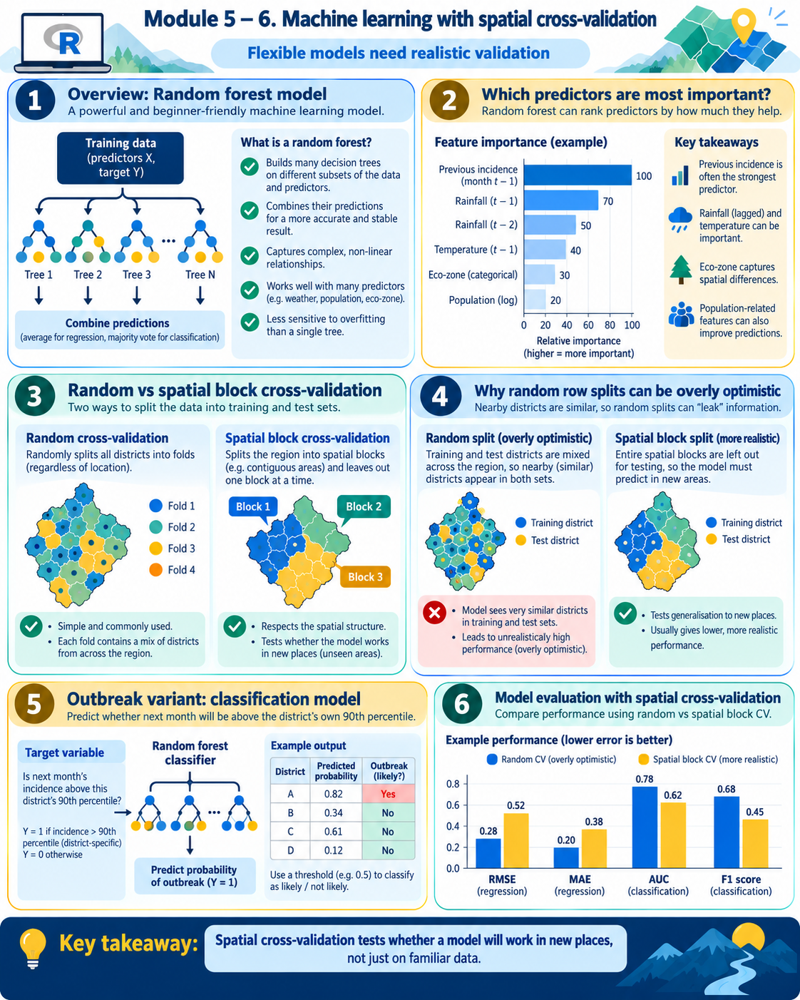
</div>


## 4.4 Step by step in R with Ama's data

Step 1. The forest, the test score.

In [ ]:
feats <- c("inc_lag1", "rain_lag1", "rain_lag2", "tmean_lag1", "month_of_year", "eco_zone", "elev_m", "ndvi", "pop_density", "fac_per_10k")
rf <- ranger(x = train[, feats], y = train$incidence_1000, num.trees = 500, importance = "permutation", seed = 1)
rf
test$pred_rf <- predict(rf, data = test[, feats])$predictions
scores <- bind_rows(scores, tibble(model = "Random forest", RMSE = round(rmse(test$incidence_1000, test$pred_rf), 2), MAE = round(mae(test$incidence_1000, test$pred_rf), 2)))
scores

Step 2. What the forest relied on.

In [ ]:
# variable importance: what the forest relied on
imp <- tibble(feature = names(rf$variable.importance), importance = rf$variable.importance) |> arrange(-importance) |> mutate(importance = round(importance, 2))
imp

In [ ]:
imp |> mutate(feature = fct_reorder(feature, importance)) |> ggplot(aes(importance, feature)) + geom_col(fill = "#010066") +
  labs(title = "Random forest: permutation importance", subtitle = "increase in prediction error when the feature is shuffled", x = "importance", y = NULL) + theme_minimal()

Step 3. Spatial block cross-validation against random cross-validation, inside the training months.

In [ ]:
# spatial cross-validation within the training months: hold out whole regions, not random rows
regions <- unique(train$region); set.seed(2); fold_of_region <- setNames(sample(rep(1:4, length.out = length(regions))), regions)
train <- train |> mutate(fold_space = fold_of_region[region], fold_random = sample(rep(1:4, length.out = n())))
cv_rmse <- function(fold_col) map_dbl(1:4, function(k) {
  tr <- train[train[[fold_col]] != k, ]; ho <- train[train[[fold_col]] == k, ]
  m  <- ranger(x = tr[, feats], y = tr$incidence_1000, num.trees = 300, seed = 1)
  rmse(ho$incidence_1000, predict(m, data = ho[, feats])$predictions) })
tibble(fold = 1:4, random_cv = round(cv_rmse("fold_random"), 2), spatial_block_cv = round(cv_rmse("fold_space"), 2))

In [ ]:
districts |> left_join(train |> distinct(adm2_code, fold_space), by = "adm2_code") |> ggplot() + geom_sf(aes(fill = factor(fold_space)), colour = "white", linewidth = 0.1) +
  scale_fill_brewer("fold", palette = "Set2") + labs(title = "Spatial block cross-validation folds", subtitle = "whole regions are held out together") + theme_minimal()

Step 4. The outbreak variant: will next month be above the district's own 90th percentile?

In [ ]:
# a classification variant: will next month be a high month (above the district's own training 90th percentile)?
thr <- train |> group_by(adm2_code) |> summarise(p90 = quantile(incidence_1000, 0.9))
train_c <- train |> left_join(thr, by = "adm2_code") |> mutate(high = factor(incidence_1000 > p90, levels = c(FALSE, TRUE)))
test_c  <- test  |> left_join(thr, by = "adm2_code") |> mutate(high = incidence_1000 > p90)
rf_c <- ranger(x = train_c[, feats], y = train_c$high, num.trees = 500, probability = TRUE, seed = 1)
test_c$p_high <- predict(rf_c, data = test_c[, feats])$predictions[, "TRUE"]
mean(test_c$high)
round(as.numeric(auc(roc(test_c$high, test_c$p_high, quiet = TRUE))), 3)
test_c |> mutate(flag = p_high > 0.3) |> summarise(flagged = sum(flag), sensitivity = round(mean(flag[high]), 2), ppv = round(mean(high[flag]), 2))

## 4.8 Trial test 4

Answer the trial test on paper (manual section 4.8). Answers are at the end of the manual.

# Topic 5 – Evaluating, Mapping and Operationalising the Forecast

### Visual explainer: From forecasts to action

*This shows how forecast metrics, ranking, mapping and confidence classes become public-health deliverables.*

<div style="text-align:center; margin: 14px 0 28px 0;">
  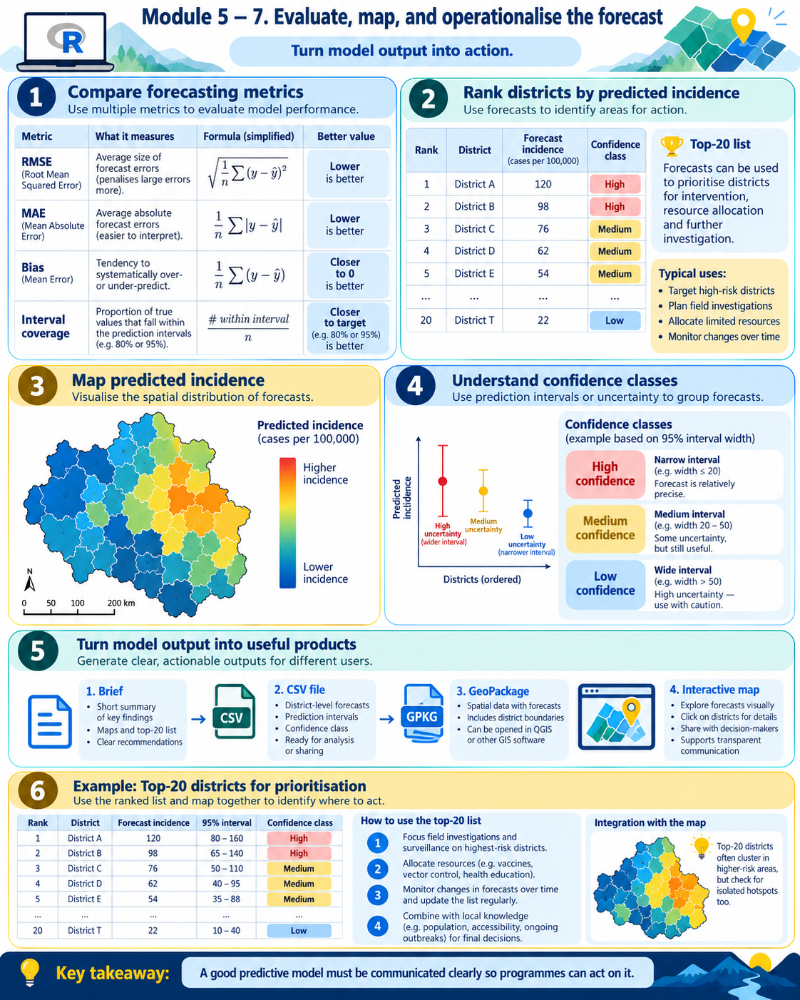
</div>


## 5.4 Step by step in R with Ama's data

Step 1. The comparison table with skill, and the error by month.

In [ ]:
scores |> mutate(skill_vs_seasonal = round(1 - RMSE / RMSE[model == "Naive: same month last year"], 2))
test |> group_by(month) |> summarise(across(c(inc_lag1, inc_seasonal, pred_glm, pred_st, pred_rf), ~ round(rmse(incidence_1000, .x), 1))) |>
  rename(last = inc_lag1, seasonal = inc_seasonal, glm = pred_glm, spatio_temporal = pred_st, forest = pred_rf)

In [ ]:
test |> select(month, adm2_code, incidence_1000, seasonal = inc_seasonal, glm = pred_glm, spatio_temporal = pred_st, forest = pred_rf) |>
  pivot_longer(c(seasonal, glm, spatio_temporal, forest), names_to = "model", values_to = "pred") |>
  group_by(month, model) |> summarise(RMSE = rmse(incidence_1000, pred), .groups = "drop") |>
  ggplot(aes(month, RMSE, colour = model)) + geom_line(linewidth = 1) + geom_point(size = 2) +
  labs(title = "Forecast error by test month, four models", x = NULL, colour = NULL) + theme_minimal() + theme(legend.position = "bottom")

Step 2. Error by district for the spatio-temporal model (the one with intervals).

In [ ]:
err <- test |> group_by(adm2_code, adm2_name, region) |> summarise(mae_st = mae(incidence_1000, pred_st), bias_st = mean(pred_st - incidence_1000), width = mean(width), .groups = "drop")
err |> arrange(-mae_st) |> mutate(across(c(mae_st, bias_st, width), ~ round(.x, 1))) |> head(6)
err |> summarise(median_mae = round(median(mae_st), 1), districts_mae_over_10 = sum(mae_st > 10))

In [ ]:
districts |> left_join(err, by = "adm2_code") |> ggplot() + geom_sf(aes(fill = mae_st), colour = "white", linewidth = 0.1) +
  scale_fill_viridis_c("MAE", option = "rocket", direction = -1, limits = c(0, 20), oob = squish) +
  labs(title = "Forecast error by district, July to December 2024", subtitle = "spatio-temporal model; mean absolute error, incidence per 1,000") + theme_minimal()

Step 3. The deliverable: the July 2024 forecast made at the end of June, ranked, with a confidence class and June's completeness.

In [ ]:
# the deliverable: the forecast for July 2024 made at the end of June 2024, with a confidence class, ranked
july <- test |> filter(month == ymd("2024-07-01")) |>
  mutate(confidence = case_when(width < 8 ~ "high", width < 16 ~ "medium", TRUE ~ "low"),   # width of the 90% interval, per 1,000
         completeness_june = rate_lag1) |>
  arrange(-pred_st) |>
  select(adm2_name, region, pred_st, st_lo, st_hi, confidence, completeness_june, observed = incidence_1000)
july |> count(confidence)
july |> mutate(across(c(pred_st, st_lo, st_hi, observed), ~ round(.x, 1))) |> print(n = 20)

196 districts could be forecast (the others lacked a usable June). The first eight are all classed 'low' confidence in absolute terms because their intervals are 20 or more per 1,000 wide, yet every one of their lower bounds is above 25: they are certainly high, and uncertain only about how high. The observed column, which the programme would not have had, shows the ranking held.

In [ ]:
mp <- districts |> left_join(test |> filter(month == ymd("2024-07-01")) |> select(adm2_code, pred_st, incidence_1000, width), by = "adm2_code")
a <- ggplot(mp) + geom_sf(aes(fill = pred_st), colour = "white", linewidth = 0.1) + scale_fill_viridis_c("per 1,000", option = "inferno", direction = -1, limits = c(0, 60), oob = squish) + labs(title = "Forecast for July 2024 (made in June)") + theme_void()
b <- ggplot(mp) + geom_sf(aes(fill = incidence_1000), colour = "white", linewidth = 0.1) + scale_fill_viridis_c("per 1,000", option = "inferno", direction = -1, limits = c(0, 60), oob = squish) + labs(title = "Observed, July 2024") + theme_void()
c <- ggplot(mp) + geom_sf(aes(fill = width), colour = "white", linewidth = 0.1) + scale_fill_viridis_c("width", option = "mako", direction = -1) + labs(title = "Width of the 90% interval") + theme_void()
a + b + c

Step 4. How good was the top-20 list, and the files for the programme.

In [ ]:
# how good was the top-20 list? districts predicted in the top 20 that were actually in the top 20 in July
top_pred <- july |> slice_head(n = 20) |> pull(adm2_name); top_obs <- july |> arrange(-observed) |> slice_head(n = 20) |> pull(adm2_name)
length(intersect(top_pred, top_obs))
write_csv(july |> slice_head(n = 20), file.path(out_dir, "priority_forecast_july2024.csv"))
st_write(districts |> select(adm2_code) |> left_join(test |> filter(month == ymd("2024-07-01")) |> select(adm2_code, pred_st, st_lo, st_hi, incidence_1000), by = "adm2_code"),
         file.path(out_dir, "forecast_july2024.gpkg"), delete_dsn = TRUE, quiet = TRUE)
list.files(out_dir)

Sixteen of the twenty districts the model ranked highest for July were in July's observed top twenty. The CSV is the priority list; the GeoPackage carries every district's forecast, interval and outcome for QGIS.

### Step 5. The forecast brief and the monthly routine

The brief is a page; Ama's follows this section. The routine is four lines a colleague can follow when the August export arrives: run the Module 2 pipeline (run_all.R) on the new export; refit the chosen models on all months to date; forecast the next month and write the priority table with confidence and completeness; score last month's forecast against what was observed and add the score to a running log. The running log is what tells the programme, after a year, whether the forecast is still worth reading.

## 5.8 Trial test 5

Answer the trial test on paper (manual section 5.8). Answers are at the end of the manual.

---
End of the module. Download anything you want to keep from the Files panel before the session ends.

## Export for the web map viewer

Added by `tools/prepare_notebooks.py`: writes the map layers listed in `layers.json`.

In [ ]:
# ---- Export for the web map viewer (added by tools/prepare_notebooks.py) ----
# Each block below is wrapped in safe(): if a step was edited or skipped, the other layers are
# still written. The viewer discovers everything through layers.json.
layers <- list()
safe <- function(label, expr) tryCatch(expr, error = function(e)
  message("Export skipped - ", label, ": ", conditionMessage(e)))
add_layer <- function(...) layers[[length(layers) + 1]] <<- list(...)
wgs <- function(x) sf::st_transform(x, 4326)

# district polygons, in lon/lat, lightly simplified for the web
web_districts <- function(d, tol = 0.002) {
  d <- wgs(d)
  keep <- intersect(c("adm2_code", "adm2_name", "region", "eco_zone"), names(d))
  suppressWarnings(sf::st_simplify(d[, keep], preserveTopology = TRUE, dTolerance = tol))
}
write_geojson <- function(x, name) {
  f <- file.path(out_dir, paste0(name, ".geojson"))
  if (file.exists(f)) file.remove(f)
  x <- dplyr::mutate(x, dplyr::across(dplyr::where(is.numeric), ~ round(.x, 4)))
  sf::st_write(x, f, driver = "GeoJSON", quiet = TRUE, layer_options = "COORDINATE_PRECISION=5")
}
# long district-month table -> one column per month (inc_2024_01, ...) + field list for the slider
widen_months <- function(df, value, prefix) {
  df <- as.data.frame(df)
  d  <- data.frame(adm2_code = df$adm2_code, key = paste0(prefix, "_", format(df$month, "%Y_%m")), v = df[[value]])
  m  <- sort(unique(df$month))
  list(wide   = tidyr::pivot_wider(d, names_from = "key", values_from = "v"),
       fields = lapply(m, function(x) list(field = paste0(prefix, "_", format(x, "%Y_%m")), label = format(x, "%b %Y"))))
}
# x/y/value data frame -> heat-point JSON for the browser + a GeoTIFF for GIS users
heat_export <- function(df, name, crs = 32630, max_pts = 25000) {
  df <- df[is.finite(df$value), c("x", "y", "value")]
  tryCatch(terra::writeRaster(terra::rast(df, type = "xyz", crs = paste0("EPSG:", crs)),
                              file.path(out_dir, paste0(name, ".tif")), overwrite = TRUE),
           error = function(e) message("GeoTIFF skipped for ", name, ": ", conditionMessage(e)))
  if (nrow(df) > max_pts) df <- df[round(seq(1, nrow(df), length.out = max_pts)), ]
  ll <- sf::st_coordinates(wgs(sf::st_as_sf(df, coords = c("x", "y"), crs = crs)))
  jsonlite::write_json(list(points = data.frame(lat = ll[, 2], lng = ll[, 1], value = df$value)),
                       file.path(out_dir, paste0(name, ".heat.json")), digits = 6)
}
im_df  <- function(im) { d <- as.data.frame(im); names(d)[3] <- "value"; d }          # spatstat image
pts_df <- function(s, col) { xy <- sf::st_coordinates(s); data.frame(x = xy[, 1], y = xy[, 2], value = s[[col]]) }

# Forecasts: monthly forecast vs observed (shared scale), skill by district, July priority, CV folds
safe("forecast map", {
  fc <- widen_months(test, "pred_st", "fc"); ob <- widen_months(test, "incidence_1000", "ob")
  d <- web_districts(districts) |> dplyr::left_join(fc$wide, by = "adm2_code") |> dplyr::left_join(ob$wide, by = "adm2_code")
  if (exists("err")) d <- dplyr::left_join(d, dplyr::select(err, adm2_code, mae_st, bias_st, interval_width = width), by = "adm2_code")
  jul <- test |> dplyr::filter(month == lubridate::ymd("2024-07-01")) |>
    dplyr::transmute(adm2_code, forecast_july = pred_st, observed_july = incidence_1000,
                     confidence = dplyr::case_when(width < 8 ~ "high", width < 16 ~ "medium", TRUE ~ "low"))
  d <- dplyr::left_join(d, jul, by = "adm2_code")
  if (exists("test_c")) d <- dplyr::left_join(d, test_c |> dplyr::filter(month == lubridate::ymd("2024-07-01")) |>
                                              dplyr::select(adm2_code, p_high_july = p_high), by = "adm2_code")
  if (exists("train") && "fold_space" %in% names(train))
    d <- dplyr::left_join(d, train |> dplyr::distinct(adm2_code, fold_space) |> dplyr::mutate(cv_fold = paste("Fold", fold_space)) |>
                            dplyr::select(adm2_code, cv_fold), by = "adm2_code")
  write_geojson(d, "forecast_districts")
  add_layer(id = "forecast", title = "Monthly forecast vs observed (per 1,000)", kind = "choropleth", file = "forecast_districts.geojson",
    series = list(list(id = "fc", label = "Forecast (spatio-temporal)", fields = fc$fields),
                  list(id = "ob", label = "Observed", fields = ob$fields)))
  flds <- list(
    list(field = "confidence",    label = "July forecast confidence", type = "category",
         colors = list(high = "#2A7F62", medium = "#E6A23C", low = "#C43D2A")),
    list(field = "forecast_july", label = "July forecast (per 1,000)", type = "numeric"),
    list(field = "mae_st",        label = "Forecast error, Jul-Dec (MAE)", type = "numeric"),
    list(field = "bias_st",       label = "Forecast bias, Jul-Dec", type = "numeric"),
    list(field = "interval_width", label = "Width of the 90% interval", type = "numeric"),
    list(field = "p_high_july",   label = "Probability of a high month (forest)", type = "numeric"),
    list(field = "cv_fold",       label = "Spatial cross-validation fold", type = "category"))
  flds <- Filter(function(f) f$field %in% names(d), flds)
  add_layer(id = "skill", title = "Forecast skill and priority", kind = "choropleth", file = "forecast_districts.geojson",
            source = "forecast_july2024.gpkg", fields = flds) })
safe("scores", if (exists("scores")) readr::write_csv(scores, file.path(out_dir, "model_scores.csv")))

jsonlite::write_json(list(layers = layers), file.path(out_dir, "layers.json"),
                     auto_unbox = TRUE, null = "null", na = "null")
cat("Exported", length(layers), "map layer(s) to", out_dir, "\n")
print(list.files(out_dir))
